## Implementation of Linear regression using python

In [1]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [2]:
df = pd.read_csv('Food_Delivery_Times.csv')
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [3]:
# Check size, data types and missing values
print(df.shape)
print(df.isnull().sum())
df[['Distance_km', 'Delivery_Time_min']].describe()

(1000, 9)
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


,Distance_km,Delivery_Time_min
count,1000.000000,1000.000000
mean,10.059970,56.732000
std,5.696656,22.070915
min,0.590000,8.000000
25%,5.105000,41.000000
50%,10.190000,55.500000
75%,15.017500,71.000000
max,19.990000,153.000000


### Standardize numerical features

In [4]:
# Scale the numerical columns used in the simple (one-feature) model to the range [0, 1]
scaler = MinMaxScaler()
df[['Distance_km', 'Delivery_Time_min']] = scaler.fit_transform(df[['Distance_km', 'Delivery_Time_min']])
df[['Distance_km', 'Delivery_Time_min']].head()

,Distance_km,Delivery_Time_min
0,0.378351,0.241379
1,0.815979,0.524138
2,0.460309,0.351724
3,0.353093,0.200000
4,0.950515,0.413793


## Prepare dependant and independant variables

In [5]:
# Independent variable (feature): Distance_km
X = df[['Distance_km']].values
X.shape

(1000, 1)

In [6]:
# Dependent variable (target): Delivery_Time_min
Y = df[['Delivery_Time_min']].values
Y.shape

(1000, 1)

## Split the data into training and test set

In [9]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [7]:
# Create a linear regression model

model=LinearRegression()



In [9]:
## Training  Linear regressions model 

In [10]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.39]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.14]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[8.27]


In [11]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.007333279253455738
0.08563456809872833
0.06430692103021561
0.7017966480472931
[0.39341185]
[0.14394249]


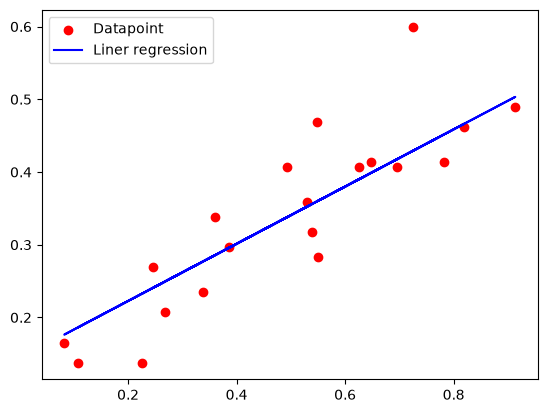

In [12]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [13]:
## Load the Height and weight  to indipendent and dependent variable 

In [15]:
hw = pd.read_csv('weight-height.csv')
X = hw[['Height']].values   # independent variable, shape (n, 1)
Y = hw[['Weight']].values   # dependent variable, shape (n, 1)
print(X.shape, Y.shape)

(10000, 1) (10000, 1)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [16]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [17]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [18]:
# Flatten the target to a 1-D vector so it matches the shape of X @ theta
y = Y.ravel()
y.shape

(10000,)

In [19]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)
print(y.shape)

(10000, 2)
(2, 10000)
(10000,)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [20]:
# Gradient descent for linear regression: y_hat = X . theta
m = len(y)
for i in range(iterations):
    y_hat = X @ theta                      # predictions
    error = y_hat - y                      # prediction error
    mseh.append(np.mean(error ** 2))       # cost (MSE) at this iteration
    gradient = (2 / m) * (X.T @ error)     # dMSE/dtheta
    theta = theta - learningrate * gradient

print("Learned parameters [bias, slope]:", theta)
print("Final MSE:", mseh[-1])

Learned parameters [bias, slope]: [1.32222677e-15 8.44449232e-01]
Final MSE: 0.2869054913354277


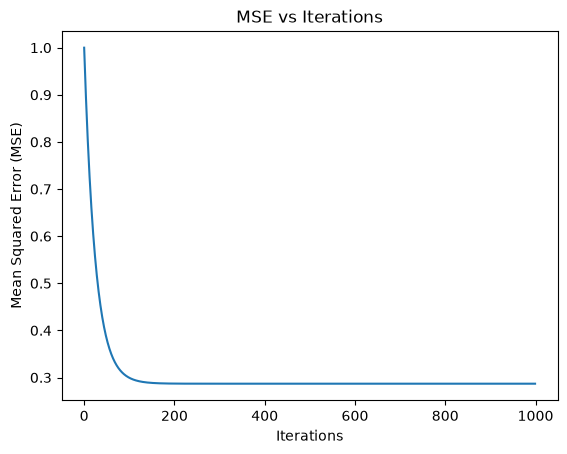

In [21]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

Rows after dropping missing values: 940
   Distance_km  Preparation_Time_min  Traffic_Level  Delivery_Time_min  \
0         7.93                    12              0                 43   
1        16.42                    20              1                 84   
2         9.52                    28              0                 59   
3         7.44                     5              1                 37   
4        19.03                    16              0                 68   

   Weather_Foggy  Weather_Rainy  Weather_Snowy  Weather_Windy  
0              0              0              0              1  
1              0              0              0              0  
2              1              0              0              0  
3              0              1              0              0  
4              0              0              0              0  

MSE : 103.23564385516656
RMSE: 10.16049427218807
MAE : 6.4913999653827315
R2  : 0.7684391491317988

Intercept: 0.8013717321892955


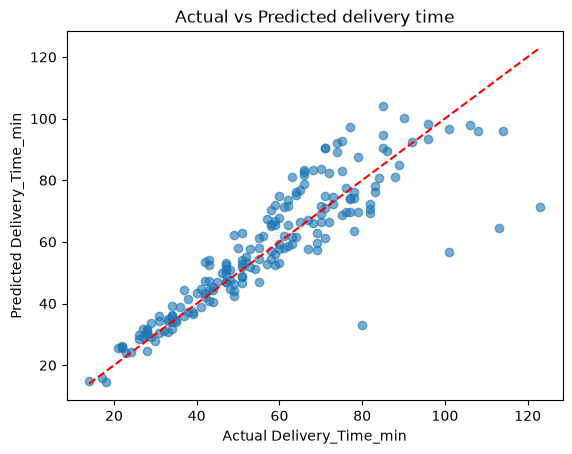

In [22]:
# ---- Food delivery time: multiple linear regression ----
food = pd.read_csv('Food_Delivery_Times.csv')

# 1. Keep only the four selected features + the target, drop rows with missing values
cols = ['Distance_km', 'Preparation_Time_min', 'Traffic_Level', 'Weather', 'Delivery_Time_min']
food = food[cols].dropna().reset_index(drop=True)
print("Rows after dropping missing values:", len(food))

# 2. Categorical encoding
# Traffic_Level is ordinal  -> label (ordinal) encoding: Low=0, Medium=1, High=2
food['Traffic_Level'] = food['Traffic_Level'].map({'Low': 0, 'Medium': 1, 'High': 2})
# Weather is nominal -> one-hot encoding (drop_first avoids the dummy-variable trap)
food = pd.get_dummies(food, columns=['Weather'], drop_first=True, dtype=int)
print(food.head())

# 3. Independent (X) and dependent (y) variables
X_f = food.drop(columns='Delivery_Time_min')
y_f = food['Delivery_Time_min']

# Train / test split
Xf_train, Xf_test, yf_train, yf_test = train_test_split(X_f, y_f, test_size=0.2, random_state=67)

# Fit the linear regression model
food_model = LinearRegression()
food_model.fit(Xf_train, yf_train)

# Evaluate
yf_pred = food_model.predict(Xf_test)
print("\nMSE :", mean_squared_error(yf_test, yf_pred))
print("RMSE:", mean_squared_error(yf_test, yf_pred) ** 0.5)
print("MAE :", mean_absolute_error(yf_test, yf_pred))
print("R2  :", r2_score(yf_test, yf_pred))

print("\nIntercept:", food_model.intercept_)
print(pd.Series(food_model.coef_, index=X_f.columns))

# Actual vs predicted
plt.scatter(yf_test, yf_pred, alpha=0.6)
plt.plot([yf_test.min(), yf_test.max()], [yf_test.min(), yf_test.max()], 'r--')
plt.xlabel('Actual Delivery_Time_min'); plt.ylabel('Predicted Delivery_Time_min')
plt.title('Actual vs Predicted delivery time'); plt.show()